In [1]:
# Jalankan jika library belum tersedia.
%pip install -q yt-dlp pandas numpy matplotlib wordcloud scikit-learn seaborn streamlit joblib openpyxl

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import re
import time
import json
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from wordcloud import WordCloud, STOPWORDS
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import joblib

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
RAW_FILE = "youtube_kesehatan_raw_final.csv"
LABELED_FILE = "youtube_kesehatan_labeled.csv"
MODEL_FILE = "sentiment_mlp_pipeline.joblib"

print("Semua library berhasil diimpor.")

Semua library berhasil diimpor.


In [3]:
RUN_SCRAPING = False  # Ubah menjadi True hanya jika ingin mengambil ulang data.

video_urls = [
    "https://youtu.be/3P24C_EMrlU",
    "https://youtu.be/tFn7dgJuyDE",
    "https://youtu.be/We3dl8c8xw4",
    "https://youtu.be/rYIty04HVHk",
]

if RUN_SCRAPING:
    import yt_dlp

    all_comments = []

    for url in video_urls:
        print("\\nMengambil:", url)

        options = {
            "quiet": True,
            "skip_download": True,
            "getcomments": True,
            "extractor_args": {
                "youtube": {
                    "max_comments": ["300,300,0,0,1"]
                }
            }
        }

        try:
            with yt_dlp.YoutubeDL(options) as ydl:
                info = ydl.extract_info(url, download=False)

            comments = info.get("comments") or []

            for comment in comments:
                all_comments.append({
                    "video_id": info.get("id"),
                    "video_title": info.get("title"),
                    "created_at": comment.get("timestamp"),
                    "username": comment.get("author"),
                    "full_text": comment.get("text")
                })

            print("Komentar diperoleh:", len(comments))

        except Exception as error:
            print("Gagal mengambil", url, ":", error)

        time.sleep(2)

    df_scraped = pd.DataFrame(all_comments)
    df_scraped = df_scraped.dropna(subset=["full_text"])
    df_scraped["full_text"] = df_scraped["full_text"].astype(str).str.strip()
    df_scraped = df_scraped[df_scraped["full_text"] != ""]
    df_scraped = df_scraped.drop_duplicates(subset=["full_text"])

    if "created_at" in df_scraped.columns:
        df_scraped["created_at"] = pd.to_datetime(
            df_scraped["created_at"], unit="s", utc=True, errors="coerce"
        ).dt.tz_convert("Asia/Jakarta")

    df_scraped.to_csv(RAW_FILE, index=False, encoding="utf-8-sig")
    print("Scraping selesai. Total komentar unik:", len(df_scraped))
else:
    print("Scraping dilewati. Notebook akan menggunakan dataset mentah yang sudah tersimpan.")

Scraping dilewati. Notebook akan menggunakan dataset mentah yang sudah tersimpan.


In [4]:
if not os.path.exists(RAW_FILE):
    raise FileNotFoundError(
        f"File {RAW_FILE} tidak ditemukan. Letakkan file CSV mentah di folder notebook."
    )

df_all = pd.read_csv(RAW_FILE)

required_columns = {"created_at", "username", "full_text"}
missing_columns = required_columns - set(df_all.columns)
if missing_columns:
    raise ValueError(f"Kolom wajib tidak ditemukan: {missing_columns}")

df_all = df_all.dropna(subset=["full_text"]).copy()
df_all["full_text"] = df_all["full_text"].astype(str).str.strip()
df_all = df_all[df_all["full_text"] != ""].copy()

print("Jumlah data mentah:", len(df_all))
print("Jumlah video:", df_all["video_id"].nunique() if "video_id" in df_all.columns else "Tidak tersedia")
print("Kolom dataset:", df_all.columns.tolist())
display(df_all.head())

Jumlah data mentah: 1796
Jumlah video: 4
Kolom dataset: ['video_id', 'video_title', 'created_at', 'username', 'full_text']


,video_id,video_title,created_at,username,full_text
0,3P24C_EMrlU,#ngopenk OBROLAN SEPUTAR JANTUNG YANG WAJIB DI...,2026-11-07 05:00:00+07:00,@yudhakusumaatmadja6847,Sederhana saja saya memahaminya : konsep aus k...
1,3P24C_EMrlU,#ngopenk OBROLAN SEPUTAR JANTUNG YANG WAJIB DI...,2026-10-27 07:00:00+07:00,@fariz_pratama_,Daging!
2,3P24C_EMrlU,#ngopenk OBROLAN SEPUTAR JANTUNG YANG WAJIB DI...,2026-10-24 07:00:00+07:00,@arsyadd9739,dok lanjutin lagi dongg episode yang iniii ter...
3,3P24C_EMrlU,#ngopenk OBROLAN SEPUTAR JANTUNG YANG WAJIB DI...,2026-10-17 07:00:00+07:00,@SarasWati-p1o,❤❤❤
4,3P24C_EMrlU,#ngopenk OBROLAN SEPUTAR JANTUNG YANG WAJIB DI...,2026-10-17 07:00:00+07:00,@muhammadrivayozipratama8462,tidak ada yang instant kecuali mie haha


In [5]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)  # URL
    text = re.sub(r"@\w+", " ", text)                       # mention
    text = re.sub(r"#", "", text)                             # tanda hashtag
    text = re.sub(r"\d+", " ", text)                        # angka
    text = re.sub(r"[^a-z\s]", " ", text)                   # simbol/emoji
    text = re.sub(r"\s+", " ", text).strip()                # spasi berlebih
    return text

def normalize_words(text):
    text = str(text).lower()
    text = re.sub(r"(.)\1{2,}", r"\1", text)  # sukaaa -> suka

    replacements = {
        "aq": "aku",
        "gw": "saya",
        "gue": "saya",
        "gak": "tidak",
        "ga": "tidak",
        "nggak": "tidak",
        "enggak": "tidak",
        "makasih": "terima kasih"
    }

    words = text.split()
    return " ".join(replacements.get(word, word) for word in words)

df_clean = df_all.copy()
df_clean["clean_text"] = df_clean["full_text"].apply(clean_text)
df_clean["clean_text"] = df_clean["clean_text"].apply(normalize_words)

jumlah_awal = len(df_clean)
df_clean = df_clean.dropna(subset=["clean_text"]).copy()
df_clean = df_clean[df_clean["clean_text"].str.strip() != ""].copy()
df_clean = df_clean.reset_index(drop=True)

print("Preprocessing selesai.")
print("Jumlah data awal:", jumlah_awal)
print("Jumlah data setelah cleansing:", len(df_clean))
print("Data yang terhapus karena teks kosong:", jumlah_awal - len(df_clean))
display(df_clean[["full_text", "clean_text"]].head(10))

Preprocessing selesai.
Jumlah data awal: 1796
Jumlah data setelah cleansing: 1756
Data yang terhapus karena teks kosong: 40


,full_text,clean_text
0,Sederhana saja saya memahaminya : konsep aus k...,sederhana saja saya memahaminya konsep aus kar...
1,Daging!,daging
2,dok lanjutin lagi dongg episode yang iniii ter...,dok lanjutin lagi dongg episode yang ini terka...
3,tidak ada yang instant kecuali mie haha,tidak ada yang instant kecuali mie haha
4,"Saya kemarin mengalami palpitasi dok, saya kir...",saya kemarin mengalami palpitasi dok saya kira...
5,"Karena saya tidak pernah olahraga, saya merasa...",karena saya tidak pernah olahraga saya merasa ...
6,Aq sukaaa sekali mendengarkan podcast dokter d...,aku suka sekali mendengarkan podcast dokter do...
7,Oh my God teman SMP 8 Jogja sekelas dan sebare...,oh my god teman smp jogja sekelas dan sebareng...
8,as a biology teacher ini sangat membantuku men...,as a biology teacher ini sangat membantuku men...
9,"Terima kasih dok, saya memiliki potensi aritmi...",terima kasih dok saya memiliki potensi aritmia...


In [6]:
positive_words = [
    "bagus", "baik", "sehat", "sembuh", "pulih",
    "bermanfaat", "membantu", "menginspirasi",
    "terima kasih", "suka", "senang", "setuju",
    "mantap", "luar biasa", "hebat", "jelas",
    "mudah", "aman", "bersyukur", "alhamdulillah",
    "semangat", "sukses", "puas", "terbaik",
    "edukatif", "menarik", "terbantu", "mengerti",
    "keren", "bagus sekali", "sangat membantu"
]

negative_words = [
    "buruk", "bahaya", "sakit", "nyeri", "sesak",
    "meninggal", "mati", "parah", "takut",
    "khawatir", "cemas", "sedih", "kecewa",
    "gagal", "susah", "sulit", "lemah",
    "darurat", "memburuk", "tidak nyaman",
    "mengecewakan", "menakutkan", "kasihan",
    "menderita", "kesakitan", "tidak enak"
]

negation_words = {
    "tidak", "bukan", "belum", "jangan",
    "tanpa", "kurang", "tidaklah"
}

def find_phrase_positions(tokens, phrase_tokens):
    n = len(phrase_tokens)
    for i in range(len(tokens) - n + 1):
        if tokens[i:i+n] == phrase_tokens:
            yield i

def label_sentiment(text):
    tokens = str(text).lower().split()
    positive_score = 0
    negative_score = 0

    def is_negated(start):
        previous_tokens = tokens[max(0, start - 2):start]
        return any(token in negation_words for token in previous_tokens)

    for phrase in positive_words:
        phrase_tokens = phrase.split()
        for start in find_phrase_positions(tokens, phrase_tokens):
            if is_negated(start):
                negative_score += 1
            else:
                positive_score += 1

    for phrase in negative_words:
        phrase_tokens = phrase.split()
        for start in find_phrase_positions(tokens, phrase_tokens):
            if is_negated(start):
                positive_score += 1
            else:
                negative_score += 1

    if positive_score > negative_score:
        label = "positif"
    elif negative_score > positive_score:
        label = "negatif"
    else:
        label = "netral"

    return pd.Series({
        "positive_score": positive_score,
        "negative_score": negative_score,
        "sentimen": label
    })

label_results = df_clean["clean_text"].apply(label_sentiment)
df_clean = pd.concat([df_clean, label_results], axis=1)

print("Pelabelan Rule-Based selesai.")
display(df_clean[["clean_text", "positive_score", "negative_score", "sentimen"]].head(10))

Pelabelan Rule-Based selesai.


,clean_text,positive_score,negative_score,sentimen
0,sederhana saja saya memahaminya konsep aus kar...,0,0,netral
1,daging,0,0,netral
2,dok lanjutin lagi dongg episode yang ini terka...,0,0,netral
3,tidak ada yang instant kecuali mie haha,0,0,netral
4,saya kemarin mengalami palpitasi dok saya kira...,0,0,netral
5,karena saya tidak pernah olahraga saya merasa ...,0,1,negatif
6,aku suka sekali mendengarkan podcast dokter do...,1,0,positif
7,oh my god teman smp jogja sekelas dan sebareng...,0,0,netral
8,as a biology teacher ini sangat membantuku men...,0,0,netral
9,terima kasih dok saya memiliki potensi aritmia...,1,0,positif


In [7]:
sentiment_order = ["positif", "negatif", "netral"]
sentiment_counts = (
    df_clean["sentimen"]
    .value_counts()
    .reindex(sentiment_order, fill_value=0)
)
sentiment_percent = (sentiment_counts / len(df_clean) * 100).round(2)

distribution_table = pd.DataFrame({
    "jumlah": sentiment_counts,
    "persentase": sentiment_percent
})
display(distribution_table)
print("Total data:", len(df_clean))

,jumlah,persentase
sentimen,,
positif,379,21.58
negatif,104,5.92
netral,1273,72.49


Total data: 1756


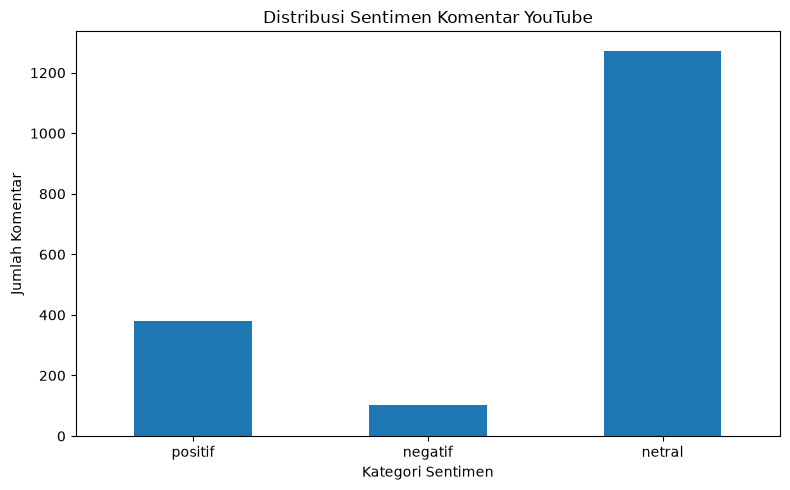

In [8]:
plt.figure(figsize=(8, 5))
sentiment_counts.plot(kind="bar")
plt.title("Distribusi Sentimen Komentar YouTube")
plt.xlabel("Kategori Sentimen")
plt.ylabel("Jumlah Komentar")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("distribusi_sentimen_bar.png", dpi=150)
plt.show()

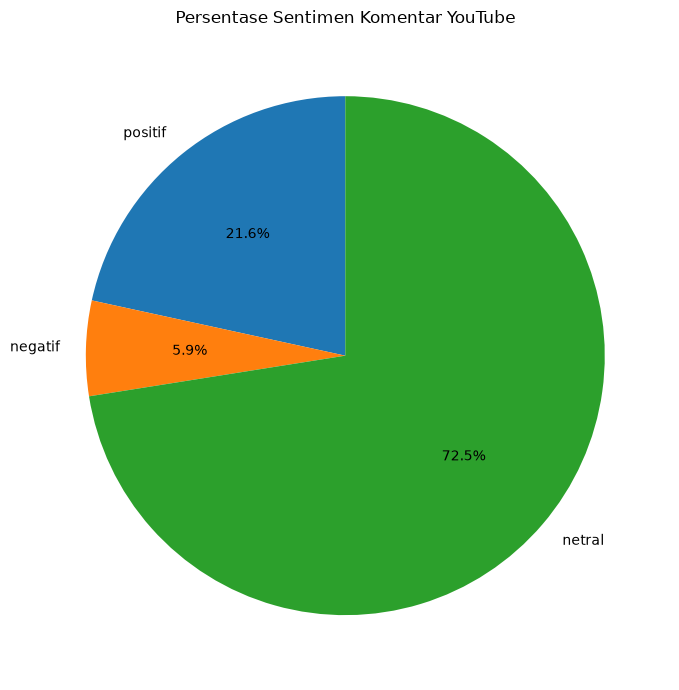

In [9]:
plt.figure(figsize=(7, 7))
plt.pie(
    sentiment_counts.values,
    labels=sentiment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Persentase Sentimen Komentar YouTube")
plt.tight_layout()
plt.savefig("distribusi_sentimen_pie.png", dpi=150)
plt.show()

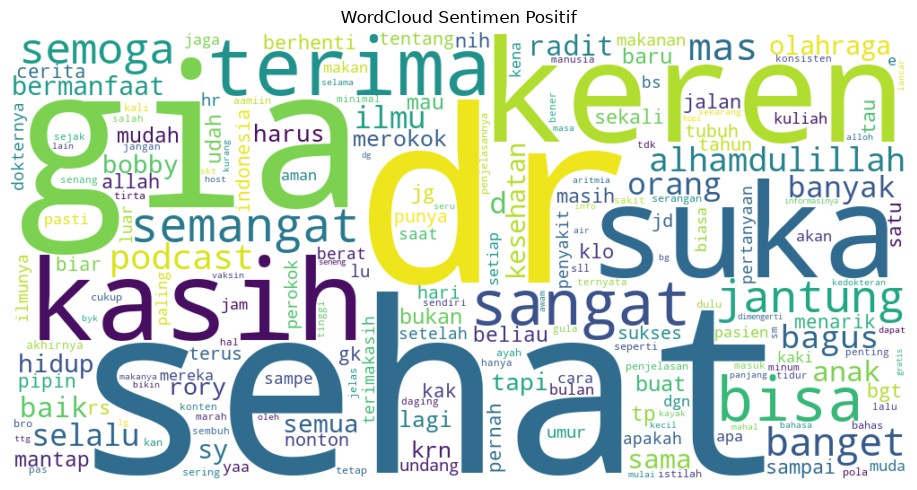

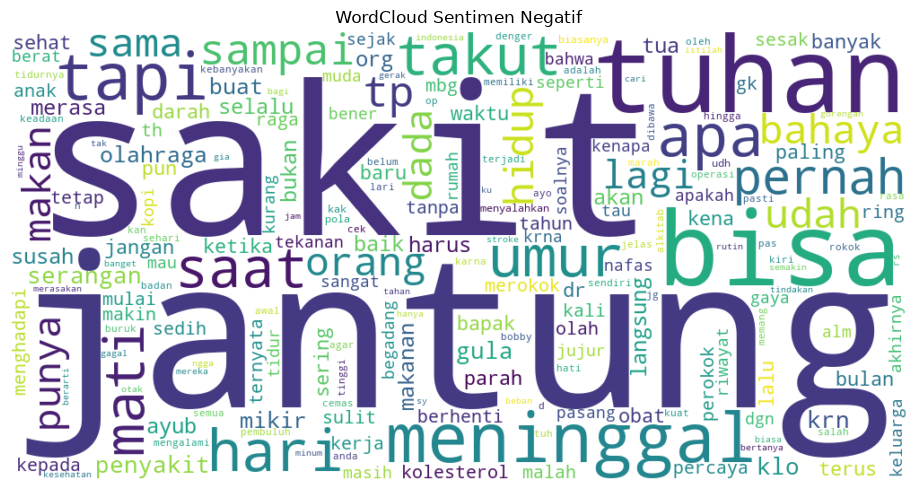

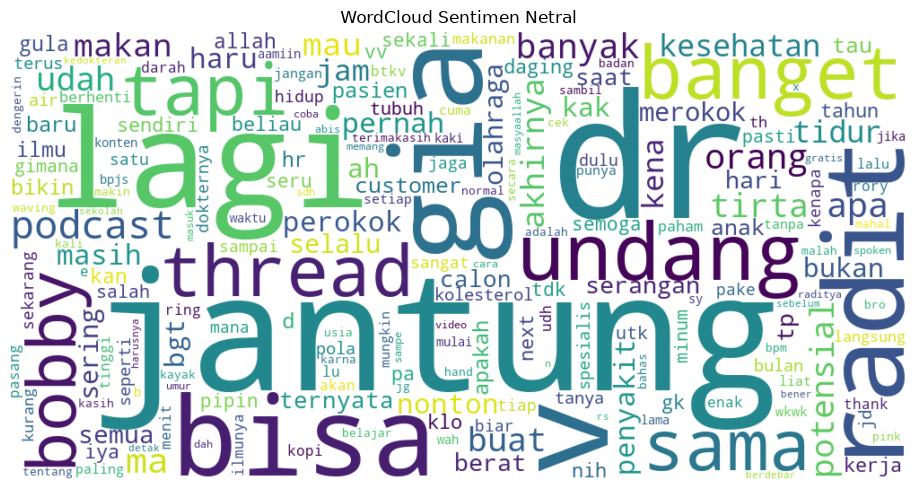

In [10]:
indonesian_stopwords = {
    "yang", "dan", "di", "ke", "dari", "ini", "itu", "saya",
    "aku", "kamu", "dia", "kami", "kita", "nya", "ya", "yg",
    "gak", "ga", "tidak", "ada", "untuk", "dengan", "karena",
    "jadi", "sudah", "saja", "aja", "lebih", "pada", "dalam",
    "dok", "dokter", "pak", "bu", "bang", "lah", "kok",
    "kalau", "kalo", "atau", "juga", "sih", "dong", "deh"
}
stopwords_all = set(STOPWORDS).union(indonesian_stopwords)

for category in sentiment_order:
    text_data = " ".join(
        df_clean.loc[df_clean["sentimen"] == category, "clean_text"].astype(str)
    )

    if not text_data.strip():
        print(f"Tidak ada teks untuk kategori {category}.")
        continue

    wc = WordCloud(
        width=1000,
        height=500,
        background_color="white",
        stopwords=stopwords_all,
        collocations=False
    ).generate(text_data)

    plt.figure(figsize=(12, 5))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title(f"WordCloud Sentimen {category.capitalize()}")
    plt.tight_layout()
    plt.savefig(f"wordcloud_{category}.png", dpi=150)
    plt.show()

In [11]:
X = df_clean["clean_text"].astype(str)
y = df_clean["sentimen"].astype(str)

print("Distribusi label sebelum split:")
print(y.value_counts())

if y.nunique() < 2:
    raise ValueError("Model membutuhkan minimal dua kelas sentimen.")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))
print("\\nDistribusi training:")
print(y_train.value_counts())
print("\\nDistribusi testing:")
print(y_test.value_counts())

Distribusi label sebelum split:
sentimen
netral     1273
positif     379
negatif     104
Name: count, dtype: int64
Jumlah data training: 1404
Jumlah data testing: 352
\nDistribusi training:
sentimen
netral     1018
positif     303
negatif      83
Name: count, dtype: int64
\nDistribusi testing:
sentimen
netral     255
positif     76
negatif     21
Name: count, dtype: int64


In [12]:
mlp_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(100,),
        activation="relu",
        solver="adam",
        max_iter=300,
        early_stopping=False,
        n_iter_no_change=15,
        random_state=RANDOM_STATE
    ))
])

mlp_pipeline.fit(X_train, y_train)
print("Training Neural Network MLP selesai.")
print("Iterasi terpakai:", mlp_pipeline.named_steps["mlp"].n_iter_)

Training Neural Network MLP selesai.
Iterasi terpakai: 109


In [13]:
y_pred = mlp_pipeline.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision_macro = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall_macro = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1_macro = f1_score(y_test, y_pred, average="macro", zero_division=0)

precision_weighted = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall_weighted = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1_weighted = f1_score(y_test, y_pred, average="weighted", zero_division=0)

metrics_df = pd.DataFrame({
    "Metrik": ["Accuracy", "Precision (Macro)", "Recall (Macro)", "F1-score (Macro)",
               "Precision (Weighted)", "Recall (Weighted)", "F1-score (Weighted)"],
    "Nilai": [accuracy, precision_macro, recall_macro, f1_macro,
              precision_weighted, recall_weighted, f1_weighted]
})

display(metrics_df)
print("\\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=sentiment_order,
    zero_division=0
))

metrics_df.to_csv("evaluasi_model.csv", index=False)

,Metrik,Nilai
0,Accuracy,0.826705
1,Precision (Macro),0.819896
2,Recall (Macro),0.599346
3,F1-score (Macro),0.659665
4,Precision (Weighted),0.821301
5,Recall (Weighted),0.826705
6,F1-score (Weighted),0.808409


\nClassification Report:
              precision    recall  f1-score   support

     positif       0.75      0.50      0.60        76
     negatif       0.88      0.33      0.48        21
      netral       0.84      0.96      0.90       255

    accuracy                           0.83       352
   macro avg       0.82      0.60      0.66       352
weighted avg       0.82      0.83      0.81       352



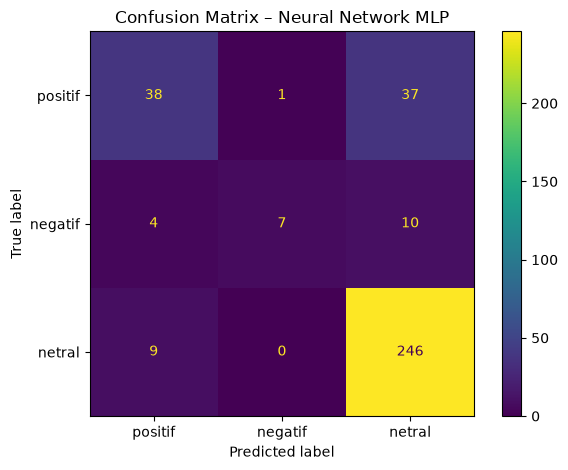

In [14]:
cm = confusion_matrix(y_test, y_pred, labels=sentiment_order)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=sentiment_order
)
disp.plot(values_format="d")
plt.title("Confusion Matrix – Neural Network MLP")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

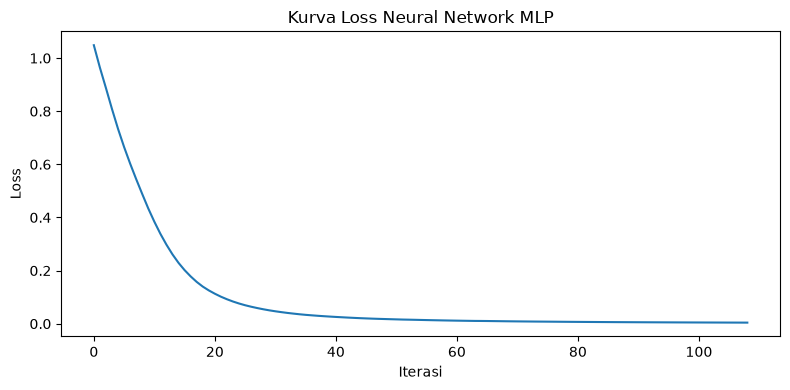

In [15]:
# Visualisasi loss selama training
loss_curve = mlp_pipeline.named_steps["mlp"].loss_curve_

plt.figure(figsize=(8, 4))
plt.plot(loss_curve)
plt.title("Kurva Loss Neural Network MLP")
plt.xlabel("Iterasi")
plt.ylabel("Loss")
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=150)
plt.show()

In [16]:
def predict_new_comment(comment):
    cleaned = normalize_words(clean_text(comment))
    prediction = mlp_pipeline.predict([cleaned])[0]
    probabilities = mlp_pipeline.predict_proba([cleaned])[0]
    classes = mlp_pipeline.named_steps["mlp"].classes_

    probability_table = pd.DataFrame({
        "sentimen": classes,
        "probabilitas": probabilities
    }).sort_values("probabilitas", ascending=False)

    emoji = {
        "positif": "😊",
        "netral": "😐",
        "negatif": "😟"
    }

    print("Komentar:", comment)
    print("Teks setelah preprocessing:", cleaned)
    print("Prediksi:", emoji.get(prediction, ""), prediction)
    display(probability_table)

# Ganti contoh komentar berikut untuk mencoba prediksi.
contoh_komentar = "Terima kasih dokter, penjelasannya sangat bermanfaat."
predict_new_comment(contoh_komentar)

Komentar: Terima kasih dokter, penjelasannya sangat bermanfaat.
Teks setelah preprocessing: terima kasih dokter penjelasannya sangat bermanfaat
Prediksi: 😊 positif


,sentimen,probabilitas
2,positif,0.999816
1,netral,0.000109
0,negatif,0.000076


In [17]:
df_clean.to_csv(LABELED_FILE, index=False, encoding="utf-8-sig")
joblib.dump(mlp_pipeline, MODEL_FILE)

with open("model_metrics.json", "w", encoding="utf-8") as file:
    json.dump({
        "accuracy": float(accuracy),
        "precision_macro": float(precision_macro),
        "recall_macro": float(recall_macro),
        "f1_macro": float(f1_macro),
        "total_data": int(len(df_clean)),
        "total_training": int(len(X_train)),
        "total_testing": int(len(X_test))
    }, file, ensure_ascii=False, indent=2)

print("Dataset berlabel disimpan:", LABELED_FILE)
print("Model disimpan:", MODEL_FILE)
print("Metrik disimpan: model_metrics.json")

Dataset berlabel disimpan: youtube_kesehatan_labeled.csv
Model disimpan: sentiment_mlp_pipeline.joblib
Metrik disimpan: model_metrics.json


In [18]:
with open('app_sentimen_nn.py', 'w', encoding='utf-8') as f:
    f.write('\nimport os\nimport re\nimport joblib\nimport pandas as pd\nimport streamlit as st\nimport matplotlib.pyplot as plt\nfrom wordcloud import WordCloud, STOPWORDS\n\nst.set_page_config(page_title="Analisis Sentimen Kesehatan", page_icon="💬", layout="wide")\n\nMODEL_FILE = "sentiment_mlp_pipeline.joblib"\nDATA_FILE = "youtube_kesehatan_labeled.csv"\n\n@st.cache_resource\ndef load_model():\n    return joblib.load(MODEL_FILE)\n\n@st.cache_data\ndef load_data():\n    return pd.read_csv(DATA_FILE)\n\ndef clean_text(text):\n    text = str(text).lower()\n    text = re.sub(r"https?://\S+|www\.\S+", " ", text)\n    text = re.sub(r"@\w+", " ", text)\n    text = re.sub(r"#", "", text)\n    text = re.sub(r"\d+", " ", text)\n    text = re.sub(r"[^a-z\s]", " ", text)\n    return re.sub(r"\s+", " ", text).strip()\n\ndef normalize_words(text):\n    text = re.sub(r"(.)\1{2,}", r"\1", str(text).lower())\n    replacements = {\n        "aq": "aku", "gw": "saya", "gue": "saya",\n        "gak": "tidak", "ga": "tidak", "nggak": "tidak",\n        "enggak": "tidak", "makasih": "terima kasih"\n    }\n    return " ".join(replacements.get(w, w) for w in text.split())\n\nst.title("💬 Dashboard Analisis Sentimen YouTube")\nst.caption("Topik: Kesehatan | Metode: Rule-Based Labeling dan Neural Network MLP")\n\nif not os.path.exists(MODEL_FILE) or not os.path.exists(DATA_FILE):\n    st.error("File model atau dataset belum tersedia. Jalankan notebook sampai bagian penyimpanan terlebih dahulu.")\n    st.stop()\n\nmodel = load_model()\ndf = load_data()\n\nif "sentimen" not in df.columns or "clean_text" not in df.columns:\n    st.error("Dataset belum memiliki kolom sentimen dan clean_text.")\n    st.stop()\n\ncounts = df["sentimen"].value_counts().reindex(["positif", "negatif", "netral"], fill_value=0)\n\nc1, c2, c3, c4 = st.columns(4)\nc1.metric("Total Komentar", f"{len(df):,}")\nc2.metric("Positif", f"{counts[\'positif\']:,}")\nc3.metric("Negatif", f"{counts[\'negatif\']:,}")\nc4.metric("Netral", f"{counts[\'netral\']:,}")\n\nst.subheader("Distribusi Sentimen")\nleft, right = st.columns(2)\n\nwith left:\n    fig, ax = plt.subplots()\n    counts.plot(kind="bar", ax=ax)\n    ax.set_xlabel("Sentimen")\n    ax.set_ylabel("Jumlah komentar")\n    ax.set_title("Jumlah Komentar per Sentimen")\n    ax.tick_params(axis="x", rotation=0)\n    st.pyplot(fig)\n    plt.close(fig)\n\nwith right:\n    fig, ax = plt.subplots()\n    ax.pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90)\n    ax.set_title("Persentase Sentimen")\n    st.pyplot(fig)\n    plt.close(fig)\n\nst.subheader("WordCloud")\ntabs = st.tabs(["Positif", "Negatif", "Netral"])\nfor tab, category in zip(tabs, ["positif", "negatif", "netral"]):\n    with tab:\n        text_data = " ".join(df.loc[df["sentimen"] == category, "clean_text"].dropna().astype(str))\n        if text_data.strip():\n            stopwords = set(STOPWORDS).union({\n                "yang", "dan", "di", "ke", "dari", "ini", "itu", "saya",\n                "aku", "kamu", "nya", "ya", "yg", "untuk", "dengan",\n                "karena", "jadi", "sudah", "saja", "aja", "dok", "dokter"\n            })\n            wc = WordCloud(width=1000, height=450, background_color="white",\n                           stopwords=stopwords, collocations=False).generate(text_data)\n            fig, ax = plt.subplots(figsize=(12, 5))\n            ax.imshow(wc, interpolation="bilinear")\n            ax.axis("off")\n            st.pyplot(fig)\n            plt.close(fig)\n        else:\n            st.info("Tidak ada teks pada kategori ini.")\n\nst.subheader("Prediksi Sentimen Komentar Baru")\ncomment = st.text_area("Masukkan komentar", placeholder="Contoh: Terima kasih dokter, penjelasannya sangat bermanfaat.")\nif st.button("Prediksi Sentimen", type="primary"):\n    if not comment.strip():\n        st.warning("Masukkan komentar terlebih dahulu.")\n    else:\n        cleaned = normalize_words(clean_text(comment))\n        prediction = model.predict([cleaned])[0]\n        probabilities = model.predict_proba([cleaned])[0]\n        classes = model.named_steps["mlp"].classes_\n        emoji = {"positif": "😊", "netral": "😐", "negatif": "😟"}\n        st.success(f"Hasil prediksi: {emoji.get(prediction, \'\')} {prediction.capitalize()}")\n        probability_df = pd.DataFrame({"Sentimen": classes, "Probabilitas": probabilities})\n        probability_df["Persentase"] = (probability_df["Probabilitas"] * 100).round(2)\n        st.dataframe(probability_df[["Sentimen", "Persentase"]], use_container_width=True)\n')

print('File app_sentimen_nn.py berhasil dibuat.')

File app_sentimen_nn.py berhasil dibuat.
